In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [35]:
# each point is length, width, type (0, 1)

# training dataset
data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

# testing dataset
mystery_flower = [4.5, 1]
mystery_flower2 = [2, 1.5]

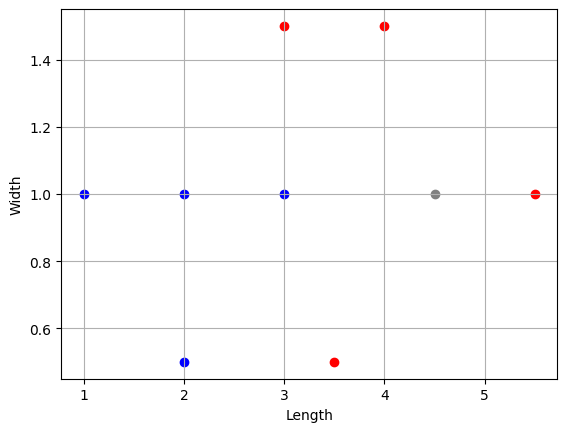

In [3]:
# scatter plot them
def vis_data():
    plt.grid()
    plt.xlabel("Length")
    plt.ylabel("Width")

    for i in range(len(data)):
        c = 'r' # 1 -> red
        if data[i][2] == 0:
            c = 'b' # 0 -> blue
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [4]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [5]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

Text(0, 0.5, "sigmoid(x) / sigmoid'(x)")

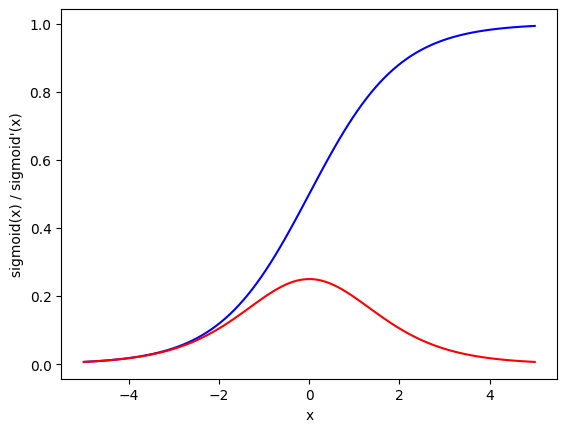

In [6]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red
plt.xlabel("x")
plt.ylabel("sigmoid(x) / sigmoid'(x)")

initial cost: 2.0731040284481566
final cost: 0.5784525791556423
final weights: 2.7642733838365134 1.0667470610787424
final bias: -8.301875994928231


Text(0, 0.5, 'Total cost over all data points')

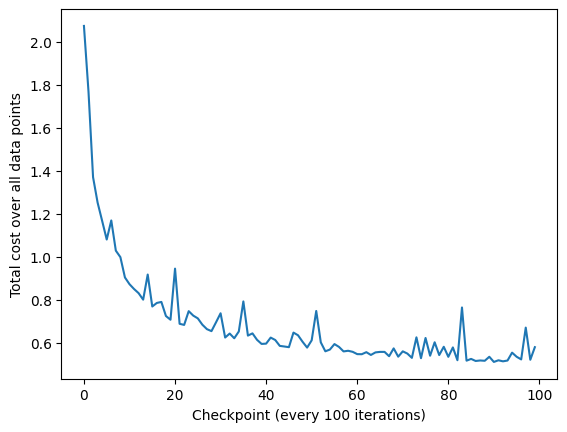

In [28]:
# train

def train():
    # random init of weights
    w1 = np.random.randn()  # weight for the length input
    w2 = np.random.randn()  # weight for the width input
    b = np.random.randn()   # bias term

    iterations = 10000       # number of training steps (one random data point per step)
    learning_rate = 0.1      # step size for gradient descent updates
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))  # pick a random index into the dataset
        point = data[ri]                    # the sampled (length, width, type) point

        z = point[0] * w1 + point[1] * w2 + b  # weighted sum (pre-activation) for this point
        pred = sigmoid(z) # networks prediction

        target = point[2]  # the true label (0 or 1) for this point

        # cost for current random point
        cost = np.square(pred - target)  # squared error between prediction and target

        # print the cost over all data points every 100 iters
        if i % 100 == 0:
            c = 0  # accumulator for total cost across the whole dataset
            for j in range(len(data)):
                p = data[j]  # j-th data point
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)  # prediction for that point with current weights
                c += np.square(p_pred - p[2])  # add its squared error to the running total
            costs.append(c)  # record the total cost at this checkpoint

        dcost_dpred = 2 * (pred - target)  # derivative of squared-error cost w.r.t. the prediction
        dpred_dz = sigmoid_p(z)             # derivative of sigmoid w.r.t. z (chain rule step)

        dz_dw1 = point[0]  # derivative of z w.r.t. w1 is just the length input
        dz_dw2 = point[1]  # derivative of z w.r.t. w2 is just the width input
        dz_db = 1          # derivative of z w.r.t. the bias is always 1

        dcost_dz = dcost_dpred * dpred_dz  # chain rule: dcost/dz = dcost/dpred * dpred/dz

        dcost_dw1 = dcost_dz * dz_dw1  # chain rule: gradient of cost w.r.t. w1
        dcost_dw2 = dcost_dz * dz_dw2  # chain rule: gradient of cost w.r.t. w2
        dcost_db = dcost_dz * dz_db    # chain rule: gradient of cost w.r.t. b

        w1 = w1 - learning_rate * dcost_dw1  # gradient descent update for w1
        w2 = w2 - learning_rate * dcost_dw2  # gradient descent update for w2
        b = b - learning_rate * dcost_db      # gradient descent update for b

    return costs, w1, w2, b  # return the cost history and the learned parameters

costs, w1, w2, b = train()  # run training and unpack the learned parameters
print("initial cost:", costs[0])
print("final cost:", costs[-1])
print("final weights:", w1, w2)
print("final bias:", b)
fig = plt.plot(costs)
plt.xlabel("Checkpoint (every 100 iterations)")
plt.ylabel("Total cost over all data points")

In [29]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9945360332511561
close to 0 -> blue, close to 1 -> red


In [36]:
# predict what the myster flower2 is!

z = w1 * mystery_flower2[0] + w2 * mystery_flower2[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.23627549807741227
close to 0 -> blue, close to 1 -> red


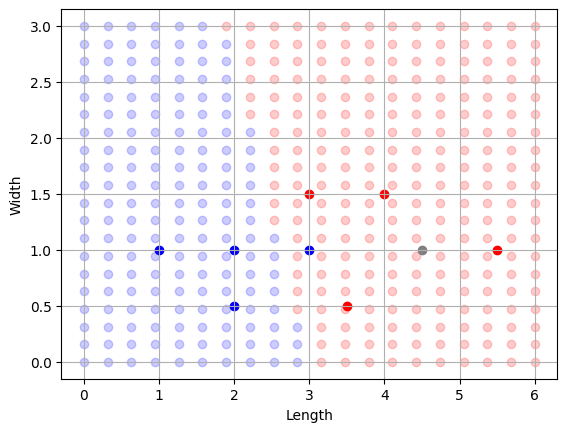

In [32]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()